# TDSC-ABUS challenge, team T1 (SZU): CLSNet, SEGNet, DETNet

## 1. Paper summary and reference

G. Luo, M. Xu, H. Chen, X. Liang, X. Tao, D. Ni, et al., *Tumor detection, segmentation and classification challenge on automated 3D breast ultrasound: the TDSC-ABUS challenge*, [arXiv:2501.15588](https://arxiv.org/abs/2501.15588) (2025).

The paper summarises a challenge, so each team gets a few sentences. We implement team T1, the winner (Sec. 3.2.1): three separate models for classification, segmentation and detection, evaluated with the challenge's metrics (Sec. 2.3). Other teams are tracked in their own issues.

In [1]:
import sys
sys.path.insert(0, "..")
from pathlib import Path
import numpy as np, pandas as pd, torch, matplotlib.pyplot as plt
from abus_classification.challenge import PUBLISHED
from abus_classification.papers.luo2025_t1 import CLSNet, DETNet, SEGNet
from abus_classification.papers.luo2025_t1 import pipeline as p

RESULTS = Path("../results/luo2025_t1")
results = RESULTS / "luo2025_t1_results.csv"
print("stored results:", results.exists())

stored results: True


## 2. Implementation details

The paper names three model families and nothing else. Every other row is our assumption.

| Item | Paper | Ours | Status |
|---|---|---|---|
| CLSNet | 3D ResNet with softmax | torchvision `r3d_18`, one input channel, two classes, no pretraining | Depth **assumed** |
| CLSNet input | Not stated | 128 x 64 x 128 patch at 0.5 mm around DETNet's top box; trained around the true centre, moved up to 12 voxels | **Assumed** |
| SEGNet | U-Net | 3D U-Net, widths 16-256, depth 4, Dice + cross-entropy | Widths and loss **assumed** |
| SEGNet inference | Not stated | Sliding window at 50% overlap, threshold 0.5, largest component | **Assumed** |
| DETNet | Single-stage, anchor-free, after CPMNet | Heatmap (CornerNet focal loss), offset and size at stride 2 on whole 1 mm volumes, top 5 peaks | CPMNet's sampling is **not** copied |
| Voxels | Not stated | 0.5 mm isotropic with area averaging | **Assumed** |
| Optimizer | Not stated | Adam, lr 1e-3 (DETNet, SEGNet), 1e-4 (CLSNet), weight decay 1e-5 | **Assumed** |
| Augmentation | Not stated | Random flips; brightness and contrast for SEGNet and CLSNet | **Assumed** |
| Stopping | Not stated | Best epoch on Validation (SEGNet: Dice on the patch around the true lesion, since sliding windows took most of each epoch), lr halved on a plateau, patience 20-30, 1.5 h per training | **Our addition** |
| Training data | Challenge: Train + Validation available | Fit on Train (100), select on Validation (30) | **Deviation** from the shared 130 |
| Test input | Docker on unseen volumes | No ground truth used; a true-centre AUC is reported only as a reference | Follows |

## 3. Verification of the implementation

Unit tests are in `test/papers_tests/test_luo2025_t1.py`: output shapes, a hand-computed focal loss, heatmap targets decoded back to the same box, window coverage, patch padding, box and mask conversion to the original grid, all three tasks trained and scored on synthetic volumes, resume from a checkpoint and a stop at the deadline.

In [2]:
x = torch.zeros(2, 1, 128, 64, 128)
for name, net in (("SEGNet", SEGNet()), ("DETNet", DETNet()), ("CLSNet", CLSNet())):
    with torch.no_grad():
        print(name, "output", tuple(net.eval()(x).shape), "parameters", f"{sum(q.numel() for q in net.parameters()):,}")
logit, heat = torch.tensor([0.0, 0.0]), torch.tensor([1.0, 0.5])
print("focal loss", round(p.heat_focal(logit, heat).item(), 5), "by hand", round((0.25 + 1 / 64) * np.log(2), 5))
boxes = torch.tensor([[20.0, 10.0, 30.0, 12.0, 6.0, 18.0]])
target, cells = p.heat_targets(boxes, (16, 8, 24))
offset = (boxes[:, :3].view(-1, 3, 1, 1, 1) - cells[None]) / 8
size = boxes[:, 3:].log().view(-1, 3, 1, 1, 1).expand_as(offset)
print("targets decode back to", p.decode(torch.cat([(target * 20 - 10)[:, None], offset, size], 1), k=1)[0][0, 0].numpy().round(3))

SEGNet output (2, 128, 64, 128) parameters 5,646,385


DETNet output (2, 7, 64, 32, 64) parameters 1,376,567


CLSNet output (2, 2) parameters 33,148,482
focal loss 0.18412 by hand 0.18412
targets decode back to [20. 10. 30. 12.  6. 18.]


## 4. Images

**Method**: a volume goes to DETNet at 1 mm, which gives boxes; the top box centres a patch for CLSNet; SEGNet slides over the volume at 0.5 mm. The three models train separately, and CLSNet reads only DETNet's output. **Our outputs**: training curves below.

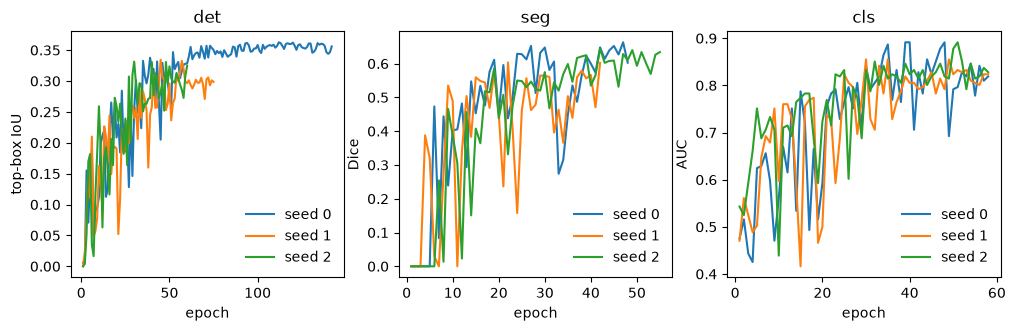

In [3]:
histories = sorted(RESULTS.glob("*_history.csv"))
if histories:
    fig, ax = plt.subplots(1, 3, figsize=(12, 3.2))
    for a, task in zip(ax, ("det", "seg", "cls")):
        for s in range(3):
            h = pd.read_csv(RESULTS / f"luo2025_t1_{task}_seed{s}_history.csv")
            a.plot(h.epoch, h.val, label=f"seed {s}")
        a.set(title=task, xlabel="epoch", ylabel={"det": "top-box IoU", "seg": "Dice", "cls": "AUC"}[task]); a.legend(frameon=False)
    plt.show()
else:
    print("not run yet")

## 5. Tables

T1's published row next to ours. Our seeds are in the second table; the challenge reports no seed variance. **This run does not reproduce T1.** The paper has no ablations for T1.

### Challenge benchmark

Our method locates the lesion itself on every task, so it is comparable with the challenge entries, except that it was scored on the released Test labels rather than through the challenge's Docker system.

In [4]:
display(PUBLISHED.loc[["T1 SZU"]])
if results.exists():
    display(pd.read_csv(results, index_col=0))
    display(pd.read_csv(RESULTS / "luo2025_t1_benchmark.csv", index_col=0).T)
else:
    print("not run yet")

,DICE,HD,ACC,AUC,FROC
T1 SZU,0.5861,117.1939,0.7571,0.8892,0.8468


,AUC,Acc,Prec,Sens,Spec,F1,AUC_gt_centre,ACC,DICE,HD,empty_cases,FROC
seed 0,0.7083,0.6000,0.5968,0.9250,0.1667,0.7255,0.7500,0.6000,0.1562,230.1701,29.0000,0.5793
seed 1,0.6658,0.6143,0.6585,0.6750,0.5333,0.6667,0.6492,0.6143,0.0928,245.4053,1.0000,0.4670
seed 2,0.6633,0.6000,0.6250,0.7500,0.4000,0.6818,0.6942,0.6000,0.0875,288.7380,13.0000,0.5364
mean of seeds,0.6792,0.6048,0.6268,0.7833,0.3667,0.6913,0.6978,0.6048,0.1122,254.7711,14.3333,0.5276
"ensemble, classification only",0.6892,0.6143,0.6182,0.8500,0.3000,0.7158,0.7117,0.6143,NaN,NaN,NaN,NaN


,"T1 reproduced, mean of seeds"
DICE,0.1122
HD,254.7711
ACC,0.6048
AUC,0.6792
FROC,0.5276
Seg_Score,0.03052
Seg_Rank,15/15
Cls_Score,0.3181
Cls_Rank,6/9
Det_Score,0.299232


## 6. Protocol

- **Split**: fit on Train (100), select on Validation (30), report on the official Test split (70), by volume.
- **Positive class**: malignant.
- **Seeds**: 3, with AUC bootstrap CI.
- **Re-run**: see [`docs/reproductions/luo2025-t1.md`](../docs/reproductions/luo2025-t1.md). Kernel in `kaggle/luo2025-t1/`.
- **Stored results**: `results/luo2025_t1/`, final weights and checkpoints on Drive in `abus-checkpoints/luo2025-t1`.

## 7. Open issues

Dice 0.112 against 0.586, HD 254.8 against 117.2, ACC 0.605 against 0.757, AUC 0.679 against 0.889, FROC 0.528 against 0.847. Last place overall among the 8 ranked entries.

- **Segmentation, [#64](https://github.com/mralinp/abus-classification/issues/64).** The trained weights are not the cause. The table below scores them on one patch instead of sliding windows, and Dice rises to about 0.47 on DETNet's box and 0.59 on the true lesion. This was found on Test and the true-lesion column uses ground truth, so neither is a result; the stored run stays the reported one. Current hypothesis: window averaging pushes lesions below 0.5, and false positives survive the largest-component step.
- **Classification, [#65](https://github.com/mralinp/abus-classification/issues/65).** Validation AUC is 0.855-0.891 and the true-centre Test AUC only 0.65-0.75, so detection is not the main loss. Lesion volume alone reaches 0.741. The paper does not say what T1's classifier reads or how it was trained ([#49](https://github.com/mralinp/abus-classification/issues/49)).
- **Detection, [#66](https://github.com/mralinp/abus-classification/issues/66).** The top box has IoU above 0.3 in 36-43 of 70 volumes. Centres are about 4 mm off and boxes too small.

In [5]:
pd.read_csv(RESULTS / "luo2025_t1_seg_inference_diagnostic.csv", index_col=0)

,sliding_window_original_grid,patch_on_det_box,patch_on_det_box_zero_cases,patch_on_true_lesion,patch_on_true_lesion_zero_cases
seed,,,,,
0,0.1562,0.4892,19,0.5997,5
1,0.0928,0.4541,16,0.5626,0
2,0.0875,0.4631,20,0.6047,1
